# 06 · Representación Bag of Words y modelos de regresión

> **Viene de:** `05_nlp_analysis` · **Lee:** `data/interim/summaries_train_clean.csv`, `data/interim/prompts_train_clean.csv` · **Produce:** `outputs/tables/06_bow_*`, `outputs/figures/06_bow_*` · **Sigue con:** `07_tfidf_analysis`

## Objetivo

Construir una representación **Bag of Words (BoW)** reproducible para los resúmenes de CommonLit, medir cómo cambia el vocabulario al exigir distintas frecuencias documentales y evaluar modelos de regresión que predigan `content` y `wording`.

La estructura sigue el patrón de `05_nlp_analysis.ipynb`: se reutiliza la tokenización del proyecto, se validan invariantes con `assert`, se exportan tablas y figuras, y cada resultado se acompaña de una interpretación en Markdown. A diferencia del análisis de n-gramas, aquí sí se construye una matriz documento-término y se prueba su capacidad predictiva.

### Decisiones metodológicas

- Se conservan las stopwords porque pueden aportar información sobre estilo y redacción.
- El vocabulario de cada modelo se ajusta únicamente con datos de entrenamiento para evitar fuga de información.
- La métrica principal es **MCRMSE**, el promedio del RMSE de `content` y `wording`, coherente con la competencia.
- Se reporta una partición estratificada por `prompt_id` para medir desempeño en prompts conocidos y una validación agrupada para medir generalización a prompts no vistos.

## 1. Carga de datos y configuración

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse

from sklearn.dummy import DummyRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import Ridge, SGDRegressor
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Normalizer

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src").is_dir() and (path / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.bow import (
    build_bow_vectorizer,
    coefficient_table,
    regression_metrics,
    vocabulary_diagnostic,
)
from src.data_loader import load_csv_files

INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
for directory in [TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

clean_files = ["summaries_train_clean.csv", "prompts_train_clean.csv"]
if not all((INTERIM_DATA_DIR / name).is_file() for name in clean_files):
    raise FileNotFoundError(
        "Faltan las copias limpias. Ejecute primero 00_data_loading.ipynb "
        "y 01_data_quality.ipynb."
    )

datasets = load_csv_files(INTERIM_DATA_DIR, clean_files)
summaries = datasets["summaries_train_clean"]
prompts = datasets["prompts_train_clean"]
targets = ["content", "wording"]

assert not summaries.empty
assert summaries["student_id"].is_unique
assert summaries["text"].notna().all() and summaries["text"].str.strip().ne("").all()
assert summaries[targets].isna().sum().eq(0).all()
assert summaries["prompt_id"].isin(prompts["prompt_id"]).all()

plt.rcParams.update({
    "figure.figsize": [10, 5],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

dataset_summary = pd.DataFrame({
    "resúmenes": [len(summaries)],
    "prompts": [summaries["prompt_id"].nunique()],
    "estudiantes_únicos": [summaries["student_id"].nunique()],
    "faltantes": [int(summaries[["text", *targets]].isna().sum().sum())],
})
display(dataset_summary)
display(summaries[["student_id", "prompt_id", "text", *targets]].head(3))

,resúmenes,prompts,estudiantes_únicos,faltantes
0,7165,4,7165,0


,student_id,prompt_id,text,content,wording
0,000e8c3c7ddb,814d6b,The third wave was an experimentto see how peo...,0.205683,0.380538
1,0020ae56ffbf,ebad26,They would rub it up with soda to make the sme...,-0.548304,0.506755
2,004e978e639e,3b9047,"In Egypt, there were many occupations and soci...",3.128928,4.231226


### Análisis del resultado de carga

Se mantienen las **7,165 observaciones**, los cuatro prompts y las dos variables objetivo del conjunto limpio. No hay textos vacíos ni objetivos faltantes, y cada `student_id` es único. Por ello no se eliminan registros antes de construir BoW. Esta comprobación también garantiza que las filas de la matriz documento-término podrán relacionarse directamente con las puntuaciones originales.

## 2. Construcción y pruebas de la representación BoW

BoW representa cada resumen como un vector de conteos. Cada columna corresponde a un token del vocabulario y cada fila a un resumen. Se usa `src.tokenization.tokenize_text`, la misma función del análisis de lenguaje anterior, para evitar discrepancias entre contribuciones.

In [2]:
bow_full = build_bow_vectorizer(min_df=1, max_df=0.98, binary=False)
X_bow_full = bow_full.fit_transform(summaries["text"])
feature_names_full = bow_full.get_feature_names_out()

# Pruebas de forma, tipo, vocabulario y contenido.
assert sparse.isspmatrix_csr(X_bow_full)
assert X_bow_full.shape[0] == len(summaries)
assert X_bow_full.shape[1] == len(bow_full.vocabulary_)
assert len(feature_names_full) == len(set(feature_names_full))
assert X_bow_full.nnz > 0 and np.isfinite(X_bow_full.data).all()
assert X_bow_full.data.min() >= 1
assert np.allclose(X_bow_full.data, np.round(X_bow_full.data))

example_index = 0
example_row = X_bow_full.getrow(example_index)
example_counts = (
    pd.DataFrame({
        "token": feature_names_full[example_row.indices],
        "conteo": example_row.data.astype(int),
    })
    .sort_values(["conteo", "token"], ascending=[False, True])
    .head(15)
    .reset_index(drop=True)
)

matrix_summary = pd.DataFrame([{
    "documentos": X_bow_full.shape[0],
    "vocabulario": X_bow_full.shape[1],
    "valores_no_cero": X_bow_full.nnz,
    "densidad": X_bow_full.nnz / (X_bow_full.shape[0] * X_bow_full.shape[1]),
    "dispersion": 1 - X_bow_full.nnz / (X_bow_full.shape[0] * X_bow_full.shape[1]),
}])
display(matrix_summary.round(6))
display(example_counts)
matrix_summary.to_csv(TABLES_DIR / "06_bow_matrix_summary.csv", index=False)
example_counts.to_csv(TABLES_DIR / "06_bow_example_document.csv", index=False)

,documentos,vocabulario,valores_no_cero,densidad,dispersion
0,7165,12469,350262,0.003921,0.996079


,token,conteo
0,to,5
1,people,3
2,the,3
3,as,2
4,it,2
5,leader,2
6,new,2
7,a,1
8,an,1
9,and,1


### Análisis de la matriz BoW

La matriz completa contiene 7,165 filas y 12,469 columnas. Solo 350,262 celdas son distintas de cero, por lo que la dispersión supera 99 %. Esta es una propiedad esperada: cada resumen usa una fracción pequeña del vocabulario total. El formato disperso CSR evita reservar memoria para los millones de ceros y permite entrenar modelos lineales directamente.

El ejemplo confirma que el valor almacenado es el número de apariciones del token en el resumen. BoW conserva frecuencia, pero no conserva el orden ni el contexto de las palabras; dos textos con los mismos conteos producen el mismo vector.

## 3. Sensibilidad del tamaño del vocabulario

,min_df,documentos,vocabulario,valores_no_cero,densidad,dispersion,variables_activas_por_documento,vocabulario_retenido
0,1,7165,12469,350262,0.003921,0.996079,48.885136,1.000000
1,2,7165,5536,343329,0.008656,0.991344,47.917516,0.443981
2,5,7165,3007,336739,0.015629,0.984371,46.997767,0.241158
3,10,7165,2095,330767,0.022035,0.977965,46.164271,0.168017
4,20,7165,1480,322362,0.030399,0.969601,44.991207,0.118694


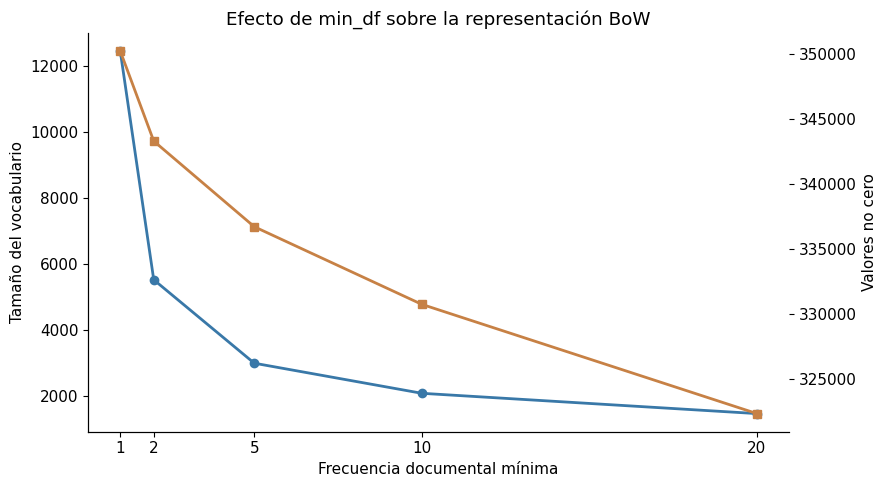

In [3]:
vocabulary_results = vocabulary_diagnostic(
    summaries["text"],
    min_document_frequencies=[1, 2, 5, 10, 20],
    max_df=0.98,
)
vocabulary_results["vocabulario_retenido"] = (
    vocabulary_results["vocabulario"] / vocabulary_results.loc[0, "vocabulario"]
)
display(vocabulary_results.round(6))
vocabulary_results.to_csv(TABLES_DIR / "06_bow_vocabulary_diagnostic.csv", index=False)

fig, ax1 = plt.subplots(figsize=[9, 5])
ax1.plot(vocabulary_results["min_df"], vocabulary_results["vocabulario"],
         marker="o", color="#3978a8", linewidth=2)
ax1.set(xlabel="Frecuencia documental mínima", ylabel="Tamaño del vocabulario",
        title="Efecto de min_df sobre la representación BoW")
ax1.set_xticks(vocabulary_results["min_df"])
ax2 = ax1.twinx()
ax2.plot(vocabulary_results["min_df"], vocabulary_results["valores_no_cero"],
         marker="s", color="#c78145", linewidth=2)
ax2.set_ylabel("Valores no cero")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_vocabulary_size.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis del tamaño del vocabulario

Con `min_df=1` se conservan 12,469 tokens. Exigir presencia en al menos dos documentos reduce el vocabulario a 5,536 variables, una disminución de 55.6 %, pero los valores no cero bajan solo de 350,262 a 343,329, cerca de 2 %. Esto indica que gran parte del vocabulario eliminado corresponde a términos extremadamente raros.

Con `min_df=5` quedan 3,007 variables y con `min_df=10`, 2,095. El filtro reduce memoria y ruido, aunque puede eliminar errores ortográficos o palabras poco frecuentes que sí estén relacionadas con `wording`. Por esa razón `min_df` se trata como hiperparámetro y no se fija únicamente por el tamaño de la matriz.

## 4. Palabras con mayor presencia en BoW

,token,frecuencia_absoluta,documentos,prevalencia_documental
0,the,43484,6896,0.96246
1,and,20078,6299,0.87913
2,to,15975,5671,0.79149
3,of,14653,5586,0.77962
4,a,11841,4807,0.67090
5,it,11469,4497,0.62763
6,in,9253,4396,0.61354
7,they,8401,3576,0.49909
8,that,8089,4098,0.57195
9,was,6784,3297,0.46015


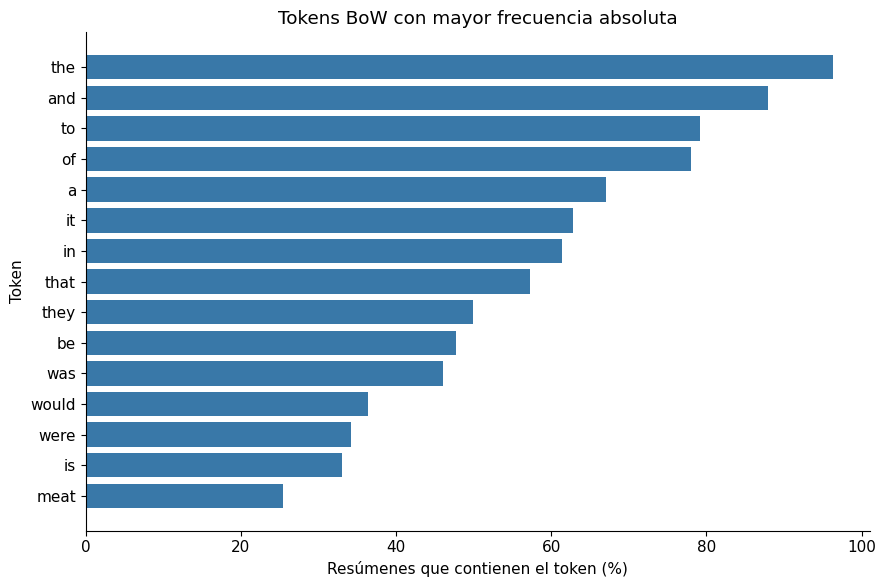

In [4]:
total_counts = np.asarray(X_bow_full.sum(axis=0)).ravel()
document_counts = np.asarray((X_bow_full > 0).sum(axis=0)).ravel()
global_bow_frequency = (
    pd.DataFrame({
        "token": feature_names_full,
        "frecuencia_absoluta": total_counts.astype(int),
        "documentos": document_counts.astype(int),
        "prevalencia_documental": document_counts / len(summaries),
    })
    .sort_values(["frecuencia_absoluta", "documentos", "token"],
                 ascending=[False, False, True])
    .reset_index(drop=True)
)
display(global_bow_frequency.head(20).round(5))
global_bow_frequency.to_csv(TABLES_DIR / "06_bow_global_frequency.csv", index=False)

plot_words = global_bow_frequency.head(15).sort_values("prevalencia_documental")
fig, ax = plt.subplots(figsize=[9, 6])
ax.barh(plot_words["token"], 100 * plot_words["prevalencia_documental"], color="#3978a8")
ax.set(title="Tokens BoW con mayor frecuencia absoluta",
       xlabel="Resúmenes que contienen el token (%)", ylabel="Token")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_top_tokens.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis de las palabras más frecuentes

Los primeros lugares están dominados por palabras funcionales del inglés: `the` aparece 43,484 veces y está presente en 96.25 % de los resúmenes. Su alta prevalencia confirma que la matriz representa tanto contenido como estilo. Este resultado coincide con el análisis de frecuencias del notebook 05, pero aquí cada palabra se convierte además en una variable predictiva.

No se eliminan stopwords automáticamente: términos funcionales pueden distinguir patrones de redacción y su utilidad se evalúa mediante validación. Al mismo tiempo, la fuerte presencia de vocabulario asociado al tema obliga a comprobar si el modelo generaliza cuando recibe un prompt no visto.

## 5. Partición de entrenamiento, validación y prueba

In [5]:
all_indices = np.arange(len(summaries))
train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=42,
    stratify=summaries["prompt_id"],
)
inner_train_indices, validation_indices = train_test_split(
    train_indices,
    test_size=0.20,
    random_state=42,
    stratify=summaries.loc[train_indices, "prompt_id"],
)

assert set(train_indices).isdisjoint(test_indices)
assert set(inner_train_indices).isdisjoint(validation_indices)
assert set(inner_train_indices).union(validation_indices) == set(train_indices)

split_labels = pd.Series("prueba", index=summaries.index)
split_labels.loc[inner_train_indices] = "entrenamiento"
split_labels.loc[validation_indices] = "validación"
split_distribution = (
    pd.crosstab(split_labels, summaries["prompt_id"], normalize="index")
    .rename_axis(index="partición")
)
split_counts = split_labels.value_counts().rename_axis("partición").to_frame("filas")
display(split_counts)
display(split_distribution.round(4))
split_counts.to_csv(TABLES_DIR / "06_bow_split_counts.csv")
split_distribution.to_csv(TABLES_DIR / "06_bow_split_prompt_distribution.csv")

,filas
partición,
entrenamiento,4585
prueba,1433
validación,1147


prompt_id,39c16e,3b9047,814d6b,ebad26
partición,,,,
entrenamiento,0.2872,0.2803,0.1540,0.2785
prueba,0.2868,0.2805,0.1542,0.2784
validación,0.2868,0.2807,0.1534,0.2790


### Análisis de la partición

La prueba final contiene 1,433 resúmenes y no interviene en la selección de parámetros. El resto se divide en 4,585 filas de entrenamiento interno y 1,147 de validación. La estratificación mantiene representados los cuatro prompts en todas las particiones, con diferencias menores a una décima de punto porcentual, de modo que la evaluación principal mide generalización a nuevos resúmenes de temas conocidos.

Esta evaluación no demuestra desempeño ante un texto fuente nuevo. Esa limitación se aborda después con `GroupKFold`, donde cada fold deja un `prompt_id` completo fuera del entrenamiento.

## 6. Prueba de min_df y regularización

,min_df,alpha,vocabulario,tiempo_entrenamiento_s,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,1,100.0,9724,0.02713,0.49752,0.39184,0.79030,0.67736,0.53557,0.60251,0.58744
1,2,100.0,4390,0.02323,0.49782,0.39190,0.79005,0.67777,0.53604,0.60203,0.58779
2,5,100.0,2437,0.02270,0.49874,0.39276,0.78927,0.67909,0.53706,0.60048,0.58891
3,10,100.0,1687,0.02239,0.50011,0.39353,0.78811,0.68267,0.53911,0.59626,0.59139
4,1,10.0,9724,0.07282,0.50619,0.39349,0.78293,0.67713,0.53037,0.60278,0.59166
5,2,10.0,4390,0.06101,0.50940,0.39546,0.78017,0.68083,0.53287,0.59843,0.59511
6,5,10.0,2437,0.04969,0.51354,0.39898,0.77657,0.68719,0.53969,0.59090,0.60037
7,10,10.0,1687,0.04507,0.51660,0.39921,0.77391,0.69627,0.54417,0.58002,0.60643
8,1,1.0,9724,0.20082,0.58966,0.45103,0.70544,0.76583,0.58986,0.49191,0.67774
9,10,1.0,1687,0.10570,0.58068,0.44414,0.71434,0.78502,0.60924,0.46612,0.68285


Mejor configuración de validación: min_df=1, alpha=100


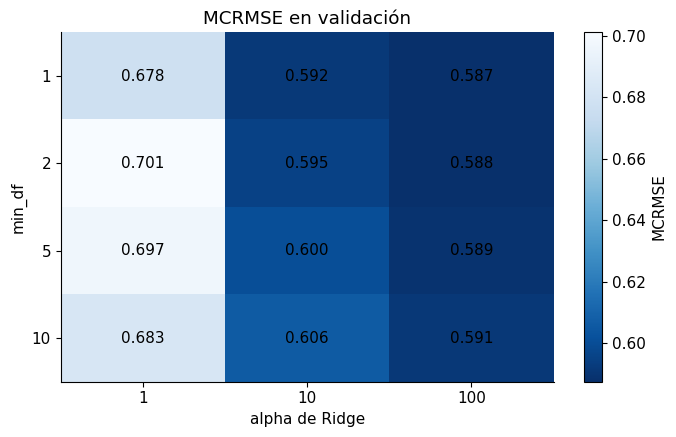

In [6]:
parameter_rows = []
for min_df in [1, 2, 5, 10]:
    vectorizer = build_bow_vectorizer(min_df=min_df, max_df=0.98, binary=True)
    X_inner = vectorizer.fit_transform(summaries.loc[inner_train_indices, "text"])
    X_validation = vectorizer.transform(summaries.loc[validation_indices, "text"])
    y_inner = summaries.loc[inner_train_indices, targets].to_numpy()
    y_validation = summaries.loc[validation_indices, targets].to_numpy()

    assert set(vectorizer.vocabulary_).issubset(set(feature_names_full))
    assert set(np.unique(X_inner.data)).issubset({1.0})
    for alpha in [1.0, 10.0, 100.0]:
        model = Ridge(alpha=alpha, solver="lsqr")
        start = perf_counter()
        model.fit(X_inner, y_inner)
        fit_seconds = perf_counter() - start
        validation_prediction = model.predict(X_validation)
        metrics = regression_metrics(y_validation, validation_prediction)
        parameter_rows.append({
            "min_df": min_df,
            "alpha": alpha,
            "vocabulario": X_inner.shape[1],
            "tiempo_entrenamiento_s": fit_seconds,
            **metrics,
        })

parameter_results = pd.DataFrame(parameter_rows).sort_values(
    ["mcrmse", "vocabulario"], ascending=[True, True]
).reset_index(drop=True)
best_min_df = int(parameter_results.loc[0, "min_df"])
best_alpha = float(parameter_results.loc[0, "alpha"])
display(parameter_results.round(5))
print(f"Mejor configuración de validación: min_df={best_min_df}, alpha={best_alpha:g}")
parameter_results.to_csv(TABLES_DIR / "06_bow_parameter_results.csv", index=False)

heatmap = parameter_results.pivot(index="min_df", columns="alpha", values="mcrmse").sort_index()
fig, ax = plt.subplots(figsize=[7, 4.5])
image = ax.imshow(heatmap, cmap="Blues_r", aspect="auto")
ax.set_xticks(range(len(heatmap.columns)), labels=[f"{value:g}" for value in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
ax.set(xlabel="alpha de Ridge", ylabel="min_df", title="MCRMSE en validación")
for row in range(heatmap.shape[0]):
    for column in range(heatmap.shape[1]):
        ax.text(column, row, f"{heatmap.iloc[row, column]:.3f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="MCRMSE")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_parameter_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis de parámetros

La comparación muestra que la regularización es decisiva. La mejor combinación es `min_df=1` y `alpha=100`, con MCRMSE de 0.58744 en validación. Con `min_df=2` el MCRMSE es 0.58779: el error aumenta apenas 0.00035 mientras el vocabulario baja de 9,724 a 4,390 variables. Los valores pequeños de `alpha` permiten coeficientes grandes y empeoran la validación, especialmente cuando el vocabulario incluye términos raros. La prueba final permanece intacta durante esta selección.

Las diferencias entre `min_df=1` y `min_df=2` suelen ser pequeñas frente a la reducción del vocabulario. Por ello se reportan tanto el mínimo error como el costo en variables, en lugar de asumir que el vocabulario más grande es automáticamente mejor.

## 7. Resultados de modelos con BoW

,modelo,vocabulario,tiempo_entrenamiento_s,tiempo_predicción_s,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,Ridge binario,11031,0.51599,0.07896,0.50817,0.38980,0.76473,0.67316,0.53242,0.58942,0.59067
1,Ridge conteos,11031,0.40870,0.06498,0.53965,0.40812,0.73468,0.68590,0.54136,0.57374,0.61277
2,SGD conteos L2,11031,1.61225,0.09749,0.85058,0.65984,0.34086,0.87912,0.68581,0.29974,0.86485
3,Dummy media,0,0.00168,0.00047,1.04773,0.81972,-0.00009,1.05076,0.83566,-0.00039,1.04924


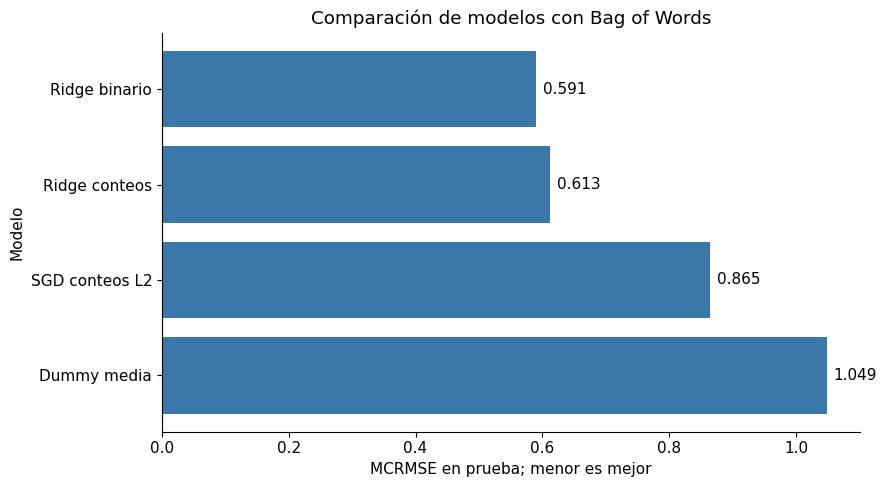

In [7]:
def make_models(min_df, alpha):
    return {
        "Dummy media": Pipeline([
            ("model", DummyRegressor(strategy="mean")),
        ]),
        "Ridge conteos": Pipeline([
            ("bow", build_bow_vectorizer(min_df=min_df, max_df=0.98, binary=False)),
            ("model", Ridge(alpha=alpha, solver="lsqr")),
        ]),
        "Ridge binario": Pipeline([
            ("bow", build_bow_vectorizer(min_df=min_df, max_df=0.98, binary=True)),
            ("model", Ridge(alpha=alpha, solver="lsqr")),
        ]),
        "SGD conteos L2": Pipeline([
            ("bow", build_bow_vectorizer(min_df=min_df, max_df=0.98, binary=False)),
            ("normalización", Normalizer(norm="l2")),
            ("model", MultiOutputRegressor(SGDRegressor(
                alpha=1e-4, max_iter=3000, tol=1e-4, random_state=42
            ))),
        ]),
    }

X_train_text = summaries.loc[train_indices, "text"]
y_train = summaries.loc[train_indices, targets].to_numpy()
X_test_text = summaries.loc[test_indices, "text"]
y_test = summaries.loc[test_indices, targets].to_numpy()

fitted_models = {}
model_predictions = {}
model_rows = []
for model_name, pipeline in make_models(best_min_df, best_alpha).items():
    start = perf_counter()
    pipeline.fit(X_train_text, y_train)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    prediction = pipeline.predict(X_test_text)
    prediction_seconds = perf_counter() - start
    metrics = regression_metrics(y_test, prediction)
    vocabulary_size = (
        len(pipeline.named_steps["bow"].vocabulary_)
        if "bow" in pipeline.named_steps else 0
    )
    model_rows.append({
        "modelo": model_name,
        "vocabulario": vocabulary_size,
        "tiempo_entrenamiento_s": fit_seconds,
        "tiempo_predicción_s": prediction_seconds,
        **metrics,
    })
    fitted_models[model_name] = pipeline
    model_predictions[model_name] = prediction

model_results = pd.DataFrame(model_rows).sort_values("mcrmse").reset_index(drop=True)
display(model_results.round(5))
model_results.to_csv(TABLES_DIR / "06_bow_model_results.csv", index=False)

plot_results = model_results.sort_values("mcrmse", ascending=False)
fig, ax = plt.subplots(figsize=[9, 5])
ax.barh(plot_results["modelo"], plot_results["mcrmse"], color="#3978a8")
ax.set(title="Comparación de modelos con Bag of Words",
       xlabel="MCRMSE en prueba; menor es mejor", ylabel="Modelo")
for index, value in enumerate(plot_results["mcrmse"]):
    ax.text(value + 0.01, index, f"{value:.3f}", va="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis de los modelos

La línea base obtiene MCRMSE de 1.04924. Ridge binario reduce el error a 0.59067, con RMSE de 0.50817 para `content` y 0.67316 para `wording`; además, explica 76.47 % y 58.94 % de la varianza de cada objetivo en esta partición. Ridge con conteos queda en 0.61277, por lo que para estos textos saber si una palabra aparece aporta más que repetirla varias veces.

SGD normalizado queda en 0.86485. Aunque es escalable, con la configuración probada queda por detrás de Ridge. El resultado indica que la solución cerrada regularizada de Ridge es una base más estable para este tamaño de corpus. La selección final se hace por MCRMSE, pero también se conservan RMSE, MAE, R cuadrado y tiempos de ejecución.

## 8. Error del mejor modelo por prompt

,prompt_id,filas,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse,prompt_title
3,ebad26,399,0.49677,0.38359,0.73591,0.62662,0.49551,0.55771,0.56170,Excerpt from The Jungle
0,39c16e,411,0.49433,0.38181,0.75953,0.65731,0.51854,0.65341,0.57582,On Tragedy
1,3b9047,402,0.50754,0.38719,0.77380,0.68698,0.53972,0.42173,0.59726,Egyptian Social Structure
2,814d6b,221,0.55308,0.42060,0.78592,0.75325,0.61162,0.57414,0.65317,The Third Wave


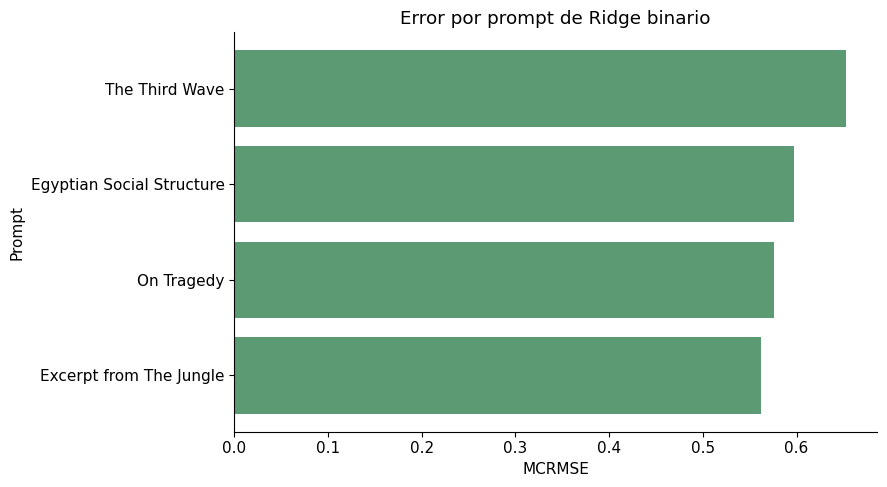

In [8]:
best_model_name = model_results.iloc[0]["modelo"]
best_test_prediction = model_predictions[best_model_name]
test_result_frame = summaries.loc[test_indices, ["student_id", "prompt_id", *targets]].copy()
test_result_frame["pred_content"] = best_test_prediction[:, 0]
test_result_frame["pred_wording"] = best_test_prediction[:, 1]
test_result_frame["error_abs_content"] = np.abs(
    test_result_frame["content"] - test_result_frame["pred_content"]
)
test_result_frame["error_abs_wording"] = np.abs(
    test_result_frame["wording"] - test_result_frame["pred_wording"]
)

prompt_metric_rows = []
for prompt_id, group in test_result_frame.groupby("prompt_id", sort=True):
    observed = group[targets].to_numpy()
    predicted = group[["pred_content", "pred_wording"]].to_numpy()
    prompt_metric_rows.append({"prompt_id": prompt_id, "filas": len(group),
                               **regression_metrics(observed, predicted)})
prompt_metrics = (
    pd.DataFrame(prompt_metric_rows)
    .merge(prompts[["prompt_id", "prompt_title"]], on="prompt_id", how="left", validate="one_to_one")
    .sort_values("mcrmse")
)
display(prompt_metrics.round(5))
prompt_metrics.to_csv(TABLES_DIR / "06_bow_best_model_by_prompt.csv", index=False)
test_result_frame.to_csv(TABLES_DIR / "06_bow_holdout_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=[9, 5])
ax.barh(prompt_metrics["prompt_title"], prompt_metrics["mcrmse"], color="#5b9a72")
ax.set(title=f"Error por prompt de {best_model_name}", xlabel="MCRMSE", ylabel="Prompt")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_error_by_prompt.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis del error por prompt

El error no es uniforme entre textos fuente. `Excerpt from The Jungle` obtiene el menor MCRMSE, 0.56170, mientras `The Third Wave` alcanza 0.65317. La diferencia de 0.09147 muestra que el vocabulario y la dificultad del tema influyen en la predicción. Por eso el resultado agregado debe acompañarse de esta tabla: un promedio bajo puede ocultar un prompt considerablemente más difícil.

Las predicciones se exportan con identificadores y errores absolutos para facilitar una revisión cualitativa posterior de los casos extremos, sin modificar los datos originales.

## 9. Prueba de generalización a prompts no vistos

,fold,prompt_prueba,filas_prueba,vocabulario_entrenamiento,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,1,39c16e,2057,10115,1.09459,0.91473,-0.27460,0.88799,0.70368,0.29214,0.99129
1,2,3b9047,2009,9154,1.06479,0.87445,0.07288,0.87956,0.70395,0.14724,0.97218
2,3,ebad26,1996,10197,0.86824,0.70858,0.23089,0.79806,0.63437,0.26368,0.83315
3,4,814d6b,1103,10739,1.10718,0.90008,0.02910,1.18027,0.98187,-0.13614,1.14373


,modelo,rmse_content,mae_content,r2_content,rmse_wording,mae_wording,r2_wording,mcrmse
0,Ridge binario GroupKFold,1.02985,0.84375,0.02599,0.91387,0.72728,0.22183,0.97186


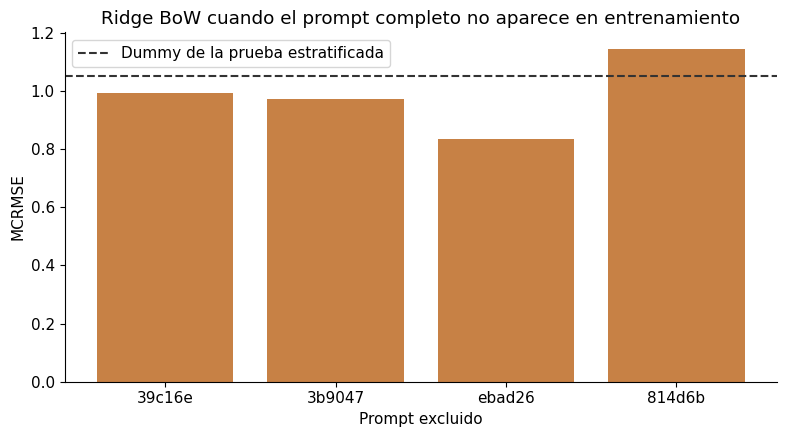

In [9]:
group_cv = GroupKFold(n_splits=summaries["prompt_id"].nunique())
group_predictions = np.full((len(summaries), len(targets)), np.nan)
group_fold_rows = []

for fold, (fold_train, fold_test) in enumerate(group_cv.split(
    summaries["text"], summaries[targets], groups=summaries["prompt_id"]
), start=1):
    pipeline = make_models(best_min_df, best_alpha)["Ridge binario"]
    pipeline.fit(summaries.iloc[fold_train]["text"], summaries.iloc[fold_train][targets])
    fold_prediction = pipeline.predict(summaries.iloc[fold_test]["text"])
    group_predictions[fold_test] = fold_prediction
    fold_metrics = regression_metrics(
        summaries.iloc[fold_test][targets].to_numpy(), fold_prediction
    )
    group_fold_rows.append({
        "fold": fold,
        "prompt_prueba": summaries.iloc[fold_test]["prompt_id"].iloc[0],
        "filas_prueba": len(fold_test),
        "vocabulario_entrenamiento": len(pipeline.named_steps["bow"].vocabulary_),
        **fold_metrics,
    })

assert np.isfinite(group_predictions).all()
group_fold_results = pd.DataFrame(group_fold_rows)
group_overall = pd.DataFrame([{
    "modelo": "Ridge binario GroupKFold",
    **regression_metrics(summaries[targets].to_numpy(), group_predictions),
}])
display(group_fold_results.round(5))
display(group_overall.round(5))
group_fold_results.to_csv(TABLES_DIR / "06_bow_group_folds.csv", index=False)
group_overall.to_csv(TABLES_DIR / "06_bow_group_overall.csv", index=False)

fig, ax = plt.subplots(figsize=[8, 4.5])
ax.bar(group_fold_results["prompt_prueba"], group_fold_results["mcrmse"], color="#c78145")
ax.axhline(model_results.loc[model_results["modelo"].eq("Dummy media"), "mcrmse"].iloc[0],
           color="#333333", linestyle="--", label="Dummy de la prueba estratificada")
ax.set(title="Ridge BoW cuando el prompt completo no aparece en entrenamiento",
       xlabel="Prompt excluido", ylabel="MCRMSE")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_unseen_prompt_stress_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis de la prueba con prompts no vistos

El MCRMSE aumenta de 0.59067 en la prueba estratificada a 0.97186 cuando cada prompt se evalúa sin ejemplos del mismo texto fuente en entrenamiento. Por fold, el error va de 0.83315 para `ebad26` a 1.14373 para `814d6b`. Esto revela que BoW aprovecha vocabulario específico del tema y generaliza mucho mejor a nuevos estudiantes del mismo prompt que a un prompt completamente nuevo.

El resultado no invalida BoW: confirma su valor como línea base interpretable y económica, pero también delimita su alcance. Para mejorar la transferencia entre prompts conviene combinar los conteos con similitud respecto al texto fuente, variables lingüísticas y representaciones semánticas.

> **Nota:** aquí `min_df` y `alpha` se eligieron con la partición estratificada (prompts conocidos). La cifra oficial de BoW con prompts no vistos, con hiperparámetros elegidos por `GroupKFold` dentro de los prompts de entrenamiento, está en `07_tfidf_analysis` y es la que se usa para comparar modelos.

## 10. Interpretación de coeficientes

,objetivo,token,coeficiente,dirección
0,content,now,-0.11722,negativa
1,content,buried,-0.08142,negativa
2,content,places,-0.07999,negativa
3,content,nothing,-0.06986,negativa
4,content,we,-0.06586,negativa
5,content,jonas,-0.06252,negativa
6,content,packers,-0.06023,negativa
7,content,been,-0.05960,negativa
8,content,rooms,-0.05822,negativa
9,content,nuisances,-0.05264,negativa


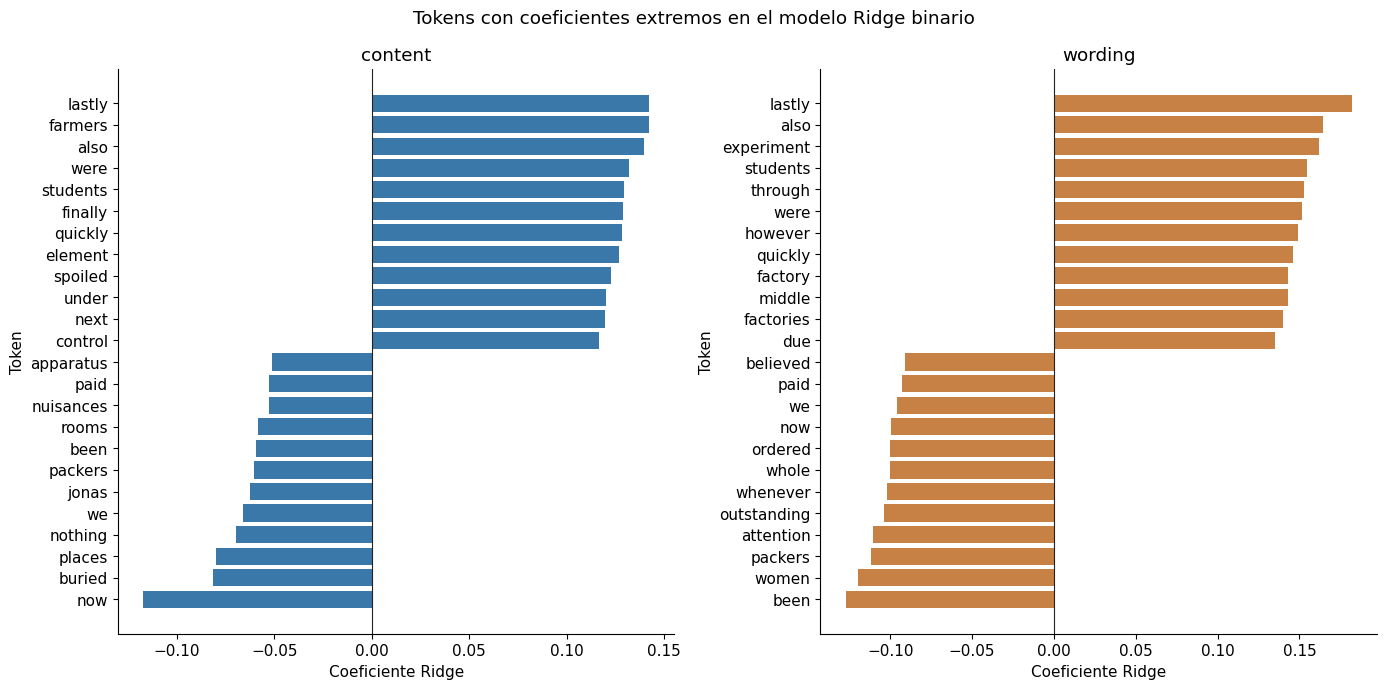

In [10]:
ridge_binary = fitted_models["Ridge binario"]
coefficient_results = coefficient_table(
    ridge_binary.named_steps["bow"].get_feature_names_out(),
    ridge_binary.named_steps["model"].coef_,
    targets=targets,
    top_n=12,
)
display(coefficient_results.round(5))
coefficient_results.to_csv(TABLES_DIR / "06_bow_ridge_coefficients.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=[14, 7])
for ax, target, color in zip(axes, targets, ["#3978a8", "#c78145"]):
    table = coefficient_results.loc[coefficient_results["objetivo"].eq(target)].sort_values("coeficiente")
    ax.barh(table["token"], table["coeficiente"], color=color)
    ax.axvline(0, color="#222222", linewidth=0.8)
    ax.set(title=target, xlabel="Coeficiente Ridge", ylabel="Token")
fig.suptitle("Tokens con coeficientes extremos en el modelo Ridge binario")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_bow_ridge_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

### Análisis de coeficientes

Los coeficientes permiten inspeccionar qué tokens desplazan cada predicción hacia valores mayores o menores manteniendo constantes las demás variables. Entre los coeficientes positivos aparecen `lastly`, `also`, `students` y `quickly`; entre los negativos aparecen `now`, `we`, `paid` y `been`. No deben interpretarse como causas: varias palabras también identifican un prompt, un nivel educativo u otras características no observadas.

La regularización reduce coeficientes extremos, pero las correlaciones entre palabras distribuyen la señal entre variables relacionadas. Esta tabla sirve para auditar el modelo y formular hipótesis, no para etiquetar palabras individuales como universalmente buenas o malas.

## 11. Pruebas finales de consistencia

In [11]:
assert vocabulary_results["vocabulario"].is_monotonic_decreasing
assert vocabulary_results["valores_no_cero"].is_monotonic_decreasing
assert model_results["mcrmse"].notna().all() and np.isfinite(model_results["mcrmse"]).all()
assert set(model_predictions) == set(model_results["modelo"])
assert all(prediction.shape == y_test.shape for prediction in model_predictions.values())
assert test_result_frame["student_id"].is_unique
assert len(test_result_frame) == len(test_indices)
assert group_fold_results["prompt_prueba"].nunique() == summaries["prompt_id"].nunique()
assert np.isfinite(coefficient_results["coeficiente"]).all()

expected_outputs = [
    TABLES_DIR / "06_bow_vocabulary_diagnostic.csv",
    TABLES_DIR / "06_bow_parameter_results.csv",
    TABLES_DIR / "06_bow_model_results.csv",
    TABLES_DIR / "06_bow_best_model_by_prompt.csv",
    TABLES_DIR / "06_bow_group_overall.csv",
    FIGURES_DIR / "06_bow_vocabulary_size.png",
    FIGURES_DIR / "06_bow_model_comparison.png",
    FIGURES_DIR / "06_bow_unseen_prompt_stress_test.png",
]
assert all(path.is_file() and path.stat().st_size > 0 for path in expected_outputs)
print(f"Pruebas aprobadas: {len(expected_outputs)} productos principales verificados.")

Pruebas aprobadas: 8 productos principales verificados.


### Análisis de las pruebas finales

Las pruebas confirman que el vocabulario y los valores no cero disminuyen al aumentar `min_df`, que todas las predicciones tienen la forma esperada, que no hay métricas no finitas y que cada prompt fue usado exactamente una vez como grupo de prueba. También se verifica la existencia de las tablas y figuras principales.

Estas comprobaciones no reemplazan una revisión científica de los resultados, pero reducen errores de implementación y permiten volver a ejecutar el notebook con confianza.

## 12. Hallazgos y limitaciones

- BoW produce una matriz altamente dispersa; el almacenamiento CSR es indispensable.
- La mayor parte del vocabulario aparece en muy pocos documentos. `min_df=2` reduce más de la mitad de las columnas con una pérdida pequeña de celdas activas.
- Ridge binario regularizado alcanza MCRMSE de 0.59067 y supera claramente el 1.04924 de la predicción por la media cuando los prompts están representados en entrenamiento.
- La presencia binaria supera al conteo, cuyo MCRMSE es 0.61277; repetir una palabra añade menos información que usarla al menos una vez en esta configuración.
- El desempeño cae a 0.97186 al excluir prompts completos. BoW aprende parte del vocabulario temático y no debe presentarse como solución suficiente para generalizar a cualquier texto fuente.
- Los coeficientes son asociaciones condicionadas por el corpus; no prueban causalidad ni calidad intrínseca de una palabra.

### Próximos pasos

Combinar BoW con las variables de longitud, diversidad, solapamiento con el prompt y el índice de registro del notebook 05; después comparar contra TF-IDF y una representación semántica bajo la misma partición y las mismas métricas.

## Puente al siguiente notebook

BoW funciona bien con prompts conocidos, pero pierde mucho con un prompt nuevo. `07_tfidf_analysis` prueba TF-IDF y la similitud con el texto fuente, y vuelve a evaluar BoW junto a los demás baselines léxicos con Leave-One-Prompt-Out y búsqueda de hiperparámetros agrupada por prompt.